# Depth of the heat-cold storage

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

## Model

Note:
- Heat equation: ∂T/∂t = κ ∂²T/∂z² with z = depth (0 at the surface, positive down), κ = 50
- T_surface(t) = a - b sin(2πt/24) with a = 15 (mean), b = 5 (fluctuation)
- Period = 24, so t is in hours. z is in m, so κ = 50 m²/h.
- "Not more than 1 degree": amplitude at the storage <= 1, so T stays between 14 and 16.

In [18]:
kappa = 50 #heat diffusion coefficient (unit: m^2/h)
a = 15 #mean temperature (unit: degree)
b = 5 #fluctuation (unit: degree)

# Surface temperature
def T_surface(t):
    return a - b*np.sin(2*np.pi*t/24)

## Spatial boundaries

Note:
- Dirichlet: I fix T at the boundary (Neumann would fix ∂T/∂z). I know T at both ends, so Dirichlet at both.
- Top (z = 0): T = T_surface(t).
- Bottom (z = L): T = 15, since at deep T is just the mean. L must be much deeper than the storage so it does not change the answer. 
- 100 nodes and L = 99 m give sequential nodes distance h = 1 m.

In [19]:
N = 100 #number of nodes
L = 99 #depth of the bottom (unit: m)

z = np.linspace(0, L, N) #depth of the nodes (0 -> 99m)
h = z[1] - z[0] #distance between the nodes (1m)

## Crank–Nicolson method

Note:
- Crank–Nicolson (section 7.7, Eq. 7.93), also used in the book for the nuclear waste rod (section 7.8): 
  (2 - H) T(t + τ) = (2 + H) T(t), with H T_i = γ (T_(i+1) + T_(i-1) - 2T_i) and γ = κτ/h^2
- τ = dt. H T_i is κτ times the three-point formula for ∂²T/∂z². Crank–Nicolson averages it over t and t + τ.
- Stable for any γ. Euler (forward difference) is only stable for γ <= 1/2 (section 7.7), and here γ = 50*0.01/1^2 = 0.5, right at the limit.

In [20]:
dt = 0.01 #time step (unit: hours)
gamma = kappa*dt/h**2

# Crank-Nicolson matrices: (2 - H) T(t + dt) = (2 + H) T(t)
# H T_i = gamma*(T_(i+1) + T_(i-1) - 2 T_i) for the inside nodes i = 1, ..., N-2
H = np.zeros((N, N))
for i in range(1, N - 1):
    H[i, i-1], H[i, i], H[i, i+1] = gamma, -2*gamma, gamma
A = 2*np.eye(N) - H #left side
B = 2*np.eye(N) + H #right side

Note:
- T(t + τ) is on the left so every step is a linear system
- Dirichlet in the matrix: first row T_0 = T_surface(t + τ), last row T_(N-1) = 15

In [21]:
# Dirichlet boundaries: row 0 and row N-1 of A just say T_0 = (value) and T_(N-1) = (value)
# The values are put in the right-hand side every step, so B is 0 in these rows
A[0, 0], A[-1, -1] = 1, 1
B[0, 0], B[-1, -1] = 0, 0

# A is the same in every step, so I do the LU decomposition only once
lu = lu_factor(A)

## Time boundaries and starting condition

Note:
- Time: t = 0 to 10 days = 240 h, dt = 0.01 h
- Start: T = 15 everywhere. This matches both boundaries at t = 0 (T_surface(0) = 15), so no jump. 
- The ground needs time to forget the start, so I only use the last day and check it against the day before

In [22]:
days = 10 #simulation time (unit: days)

# Time loop from t = 0 to t = 10 days
# Starting condition: T = 15 everywhere
# T_all keeps T at every time step and every depth
nt = int(round(days*24/dt)) #time steps
T = np.full(N, 15.0)
T_all = np.zeros((nt + 1, N))
T_all[0] = T

for n in range(nt):
    rhs = B @ T #right side (2 + H) T(t)
    rhs[0] = T_surface((n + 1)*dt)  #top: surface temperature at the new time
    rhs[-1] = 15 #bottom: mean temperature
    T = lu_solve(lu, rhs) #forward and backward substitution
    T_all[n + 1] = T

t = np.arange(nt + 1)*dt #time of every step (h)

## Amplitude and depth

Note:
- Amplitude = (max - min)/2 of T over one day.
- Last day vs the day before: checks that the start is forgotten.
- The 1 degree depth lies between two nodes, so I interpolate linearly.
- Check: for an infinitely deep ground the exact amplitude is b e^(-z/δ), δ = √(2κ/ω), ω = π/12. It is 1 degree at z = δ ln(b/1).

In [23]:
# Amplitude at every depth during one day: (max - min)/2
# day: which day (0 is the first day)
def amplitude(day):
    one_day = (t >= day*24) & (t <= (day + 1)*24)
    return (T_all[one_day].max(axis=0) - T_all[one_day].min(axis=0))/2

amp = amplitude(days - 1) #last day

# Check that the starting condition is forgotten
print("Largest difference compared to previous day:", np.max(np.abs(amp - amplitude(days - 2))), "°C")

# Depth where the amplitude is 1 degree
depth = np.interp(1, amp[::-1], z[::-1]) #np.interp needs increasing values, and amp decreases with z, so I flip both arrays

print("Where the amplitude is 1 degree:", depth, "m")

# Check exact amplitude for a ground that goes down forever - b*exp(-z/delta)
omega = 2*np.pi/24
delta = np.sqrt(2*kappa/omega)
print("Exact:", delta*np.log(b/1), "m")

Largest difference compared to previous day: 5.182668915360011e-06 °C
Where the amplitude is 1 degree: 31.438115009148273 m
Exact: 31.45501627068373 m


## Plots

T over the last day at some depths, and the amplitude against depth with the 1 degree line.

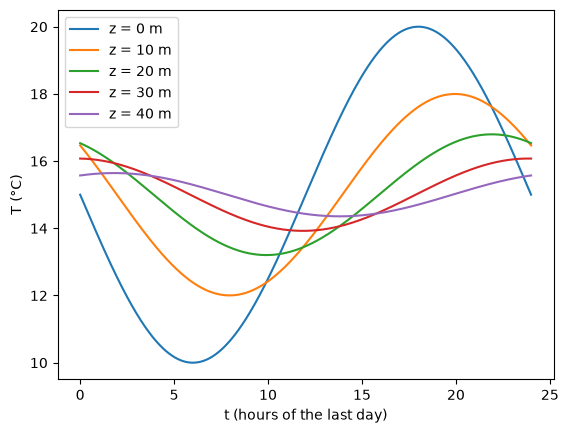

In [24]:
# Temperature during the last day at some depths
fig, ax = plt.subplots()
last = t >= (days - 1)*24
for zi in [0, 10, 20, 30, 40]:
    ax.plot(t[last] - (days - 1)*24, T_all[last, zi], label=f'z = {zi} m') #h = 1 m, so node zi is at depth zi m
ax.set_xlabel('t (hours of the last day)'); ax.set_ylabel('T (°C)'); ax.legend()
plt.show()

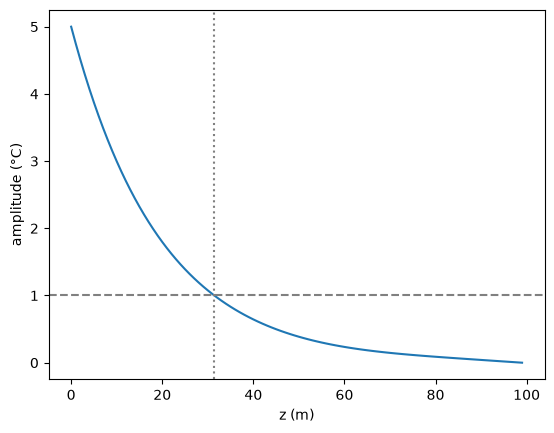

In [25]:
# Amplitude against depth, with the 1 degree line
fig, ax = plt.subplots()
ax.plot(z, amp)
ax.axhline(1, color='gray', ls='--') #1 degree
ax.axvline(depth, color='gray', ls=':') #depth found above
ax.set_xlabel('z (m)'); ax.set_ylabel('amplitude (°C)')
plt.show()

## Result
Note:
- The last two days differ by approximately 5·10^-6 so the start is forgotten.
- Deeper down the fluctuation is smaller, and the peaks arrive later also.
- The amplitude is 1 degree at z ≈ 31-32 m.
- Exact: δ ln5 ≈ 31.5 m, almost the same, so the bottom at 99 m is more than deep enough.